In [ ]:
!pip install pandas numpy scikit-learn matplotlib


Seed for train-test split: 8
Epoch 1/20
50/50 [==============================] - 8s 69ms/step - loss: 0.6913 - accuracy: 0.5317 - val_loss: 0.6966 - val_accuracy: 0.4874
Epoch 2/20
50/50 [==============================] - 0s 9ms/step - loss: 0.6889 - accuracy: 0.5493 - val_loss: 0.6992 - val_accuracy: 0.4874
Epoch 3/20
50/50 [==============================] - 1s 10ms/step - loss: 0.6886 - accuracy: 0.5493 - val_loss: 0.6999 - val_accuracy: 0.4874
Epoch 4/20
50/50 [==============================] - 1s 10ms/step - loss: 0.6887 - accuracy: 0.5493 - val_loss: 0.6984 - val_accuracy: 0.4874
Epoch 5/20
50/50 [==============================] - 0s 9ms/step - loss: 0.6883 - accuracy: 0.5493 - val_loss: 0.7015 - val_accuracy: 0.4874
Epoch 6/20
50/50 [==============================] - 1s 10ms/step - loss: 0.6884 - accuracy: 0.5493 - val_loss: 0.7002 - val_accuracy: 0.4874
Epoch 7/20
50/50 [==============================] - 1s 11ms/step - loss: 0.6883 - accuracy: 0.5493 - val_loss: 0.6995 - val_acc

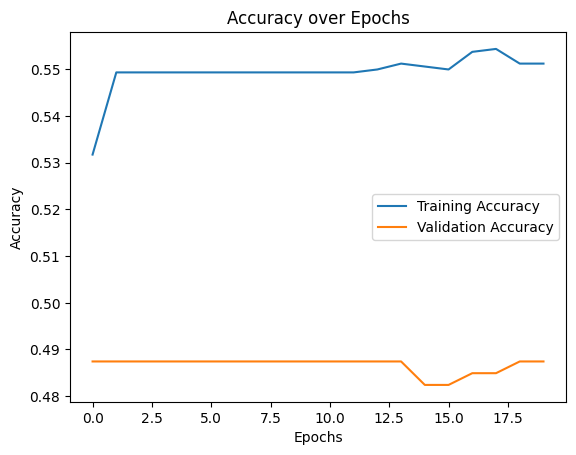

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from keras.models import Sequential
from keras.layers import LSTM, Dense
import tensorflow as tf

# Load the CSV file into a DataFrame
df = pd.read_csv('/content/drive/MyDrive/stock market/upload_DJIA_table.csv')

# Drop irrelevant columns if necessary
df = df.drop(columns=['Date'])

# Normalize the data using Min-Max scaling
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(df)

# Define features (X) and target variable (y)
X = scaled_data[:, :-1]  # Features (all columns except the last one)
y = np.where(df['Adj Close'].shift(-1) > df['Adj Close'], 1, 0)  # Target variable: 1 if next day's close price is higher, else 0

# Reshape the data for LSTM input shape (samples, time steps, features)
X = X.reshape(X.shape[0], 1, X.shape[1])

# Seed for reproducibility
seed_value = np.random.randint(1, 100)  # Random seed for train-test split
print(f"Seed for train-test split: {seed_value}")

# Split the data into training and testing sets using the random seed
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=seed_value)

# Set seeds for reproducibility within the model
np.random.seed(seed_value)
tf.random.set_seed(seed_value)

model = Sequential()
model.add(LSTM(units=50, return_sequences=True, input_shape=(X_train.shape[1], X_train.shape[2])))
model.add(LSTM(units=50))
model.add(Dense(units=1, activation='sigmoid'))

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
history = model.fit(X_train, y_train, epochs=20, batch_size=32, validation_data=(X_test, y_test), verbose=1)

# Evaluate accuracy on the test set
probabilities = model.predict(X_test)
predictions = (probabilities > 0.5).astype(int)
accuracy = accuracy_score(y_test, predictions)
print(f"Accuracy: {accuracy}")

# Plotting the accuracy graph
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from keras.models import Sequential
from keras.layers import LSTM, Dense
import tensorflow as tf

# Set seeds for reproducibility
seed_value = 42
np.random.seed(seed_value)
tf.random.set_seed(seed_value)

# Load the CSV file into a DataFrame
df = pd.read_csv('/content/drive/MyDrive/stock market/upload_DJIA_table.csv')

# Drop irrelevant columns if necessary
df = df.drop(columns=['Date'])

# Normalize the data using Min-Max scaling
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(df)

# Define features (X) and target variable (y)
X = scaled_data[:, :-1]  # Features (all columns except the last one)
y = np.where(df['Close'].shift(-1) > df['Close'], 1, 0)  # Target variable: 1 if next day's close price is higher, else 0

# Reshape the data for LSTM input shape (samples, time steps, features)
X = X.reshape(X.shape[0], 1, X.shape[1])

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=seed_value)

model = Sequential()
model.add(LSTM(units=50, return_sequences=True, input_shape=(X_train.shape[1], X_train.shape[2])))
model.add(LSTM(units=50))
model.add(Dense(units=1, activation='sigmoid'))

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
history = model.fit(X_train, y_train, epochs=20, batch_size=32, validation_data=(X_test, y_test), verbose=1)

# Evaluate accuracy on the test set
predictions = model.predict_classes(X_test)
accuracy = accuracy_score(y_test, predictions)
print(f"Accuracy: {accuracy}")

# Plotting the accuracy graph
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()


Epoch 1/20
50/50 [==============================] - 6s 24ms/step - loss: 0.6917 - accuracy: 0.5387 - val_loss: 0.6925 - val_accuracy: 0.5226
Epoch 2/20
50/50 [==============================] - 0s 5ms/step - loss: 0.6904 - accuracy: 0.5405 - val_loss: 0.6927 - val_accuracy: 0.5226
Epoch 3/20
50/50 [==============================] - 0s 6ms/step - loss: 0.6901 - accuracy: 0.5405 - val_loss: 0.6928 - val_accuracy: 0.5226
Epoch 4/20
50/50 [==============================] - 0s 5ms/step - loss: 0.6900 - accuracy: 0.5405 - val_loss: 0.6935 - val_accuracy: 0.5226
Epoch 5/20
50/50 [==============================] - 0s 5ms/step - loss: 0.6898 - accuracy: 0.5405 - val_loss: 0.6929 - val_accuracy: 0.5226
Epoch 6/20
50/50 [==============================] - 0s 5ms/step - loss: 0.6899 - accuracy: 0.5405 - val_loss: 0.6924 - val_accuracy: 0.5226
Epoch 7/20
50/50 [==============================] - 0s 6ms/step - loss: 0.6900 - accuracy: 0.5405 - val_loss: 0.6931 - val_accuracy: 0.5226
Epoch 8/20
50/50 [=

AttributeError: 'Sequential' object has no attribute 'predict_classes'

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from keras.models import Sequential
from keras.layers import LSTM, Dense


In [ ]:
# Load the CSV file into a DataFrame
df = pd.read_csv('/content/drive/MyDrive/stock market/upload_DJIA_table.csv')

# Drop irrelevant columns if necessary
df = df.drop(columns=['Date'])

# Normalize the data using Min-Max scaling
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(df)

# Define features (X) and target variable (y)
X = scaled_data[:, :-1]  # Features (all columns except the last one)
y = np.where(df['Close'].shift(-1) > df['Close'], 1, 0)  # Target variable: 1 if next day's close price is higher, else 0

# Reshape the data for LSTM input shape (samples, time steps, features)
X = X.reshape(X.shape[0], 1, X.shape[1])

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [ ]:
model = Sequential()
model.add(LSTM(units=50, return_sequences=True, input_shape=(X_train.shape[1], X_train.shape[2])))
model.add(LSTM(units=50))
model.add(Dense(units=1, activation='sigmoid'))

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])


In [ ]:
history = model.fit(X_train, y_train, epochs=20, batch_size=32, validation_data=(X_test, y_test), verbose=1)

# Evaluate accuracy on the test set
predictions = model.predict_classes(X_test)
accuracy = accuracy_score(y_test, predictions)
print(f"Accuracy: {accuracy}")


Epoch 1/20
50/50 [==============================] - 16s 39ms/step - loss: 0.6921 - accuracy: 0.5204 - val_loss: 0.6924 - val_accuracy: 0.5226
Epoch 2/20
50/50 [==============================] - 0s 5ms/step - loss: 0.6904 - accuracy: 0.5405 - val_loss: 0.6931 - val_accuracy: 0.5226
Epoch 3/20
50/50 [==============================] - 0s 6ms/step - loss: 0.6902 - accuracy: 0.5405 - val_loss: 0.6932 - val_accuracy: 0.5226
Epoch 4/20
50/50 [==============================] - 0s 9ms/step - loss: 0.6901 - accuracy: 0.5405 - val_loss: 0.6930 - val_accuracy: 0.5226
Epoch 5/20
50/50 [==============================] - 0s 9ms/step - loss: 0.6900 - accuracy: 0.5405 - val_loss: 0.6927 - val_accuracy: 0.5226
Epoch 6/20
50/50 [==============================] - 0s 9ms/step - loss: 0.6900 - accuracy: 0.5405 - val_loss: 0.6931 - val_accuracy: 0.5226
Epoch 7/20
50/50 [==============================] - 0s 8ms/step - loss: 0.6898 - accuracy: 0.5405 - val_loss: 0.6930 - val_accuracy: 0.5226
Epoch 8/20
50/50 [

AttributeError: ignored

In [ ]:
# Plotting the accuracy graph
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()


RandomForestClassifier(random_state=42)